# SBI: `P(N_HI, T | M_halo, b, V_max)`

Trains the SBIBE network (Daniel Lopez-Cano) on the `FakeSpectra_DLAs` data.

## What is being learned

`sbi` learns `q(theta | x)`. Here:

| SBIBE | Here |
|---|---|
| `theta` = cosmological parameters | `theta = (log10 N_HI, log10 T_fit)` -- what we infer |
| `xx` = `log10 P(k)`, 100 bins | `xx = (log10 M_200, log10 b/R_200, log10 V_max)` -- the conditioning |
| simulator = baccoemu | simulator = TNG50 + fake_spectra (already run, on disk) |

Note the inversion with respect to the classic use of SBI: the "observables" here are the
halo properties and the "parameters" are the absorber properties. Mathematically it is the
same thing -- conditional density estimation -- and `sbi` does not care. Physically, the
output is **an emulator of the scatter**: given a halo, the joint distribution of
`(N_HI, T)` of the sightlines that cross it.

## Pipeline

1. load one run, select `is_hcd`
2. Voigt fit -> `fit_T`, `fit_log_nhi`, `good`
3. build `theta` / `xx`, **split by `halo_id`**
4. train the MAF with `SNPE`/`NPE` (Daniel's code + version shim)
5. sample the posterior on the test set
6. corner plots: truth vs SBI

### We are going to apply a SBI-like algorithm to compute the posterior distribution $P(N_\textrm{HI}, T \mid M_\textrm{halo}, b, V_\textrm{max})$

Here what we will use for the trainig is $M_\textrm{halo}, b, V_\textrm{max}$ and we will learn **$N_\textrm{HI} \;\;\;\text{and}\;\;\; T$**

### Summary of the pipeline:

1. load the file originated from the HCD_only mode pipeline extraction. 
2. Do a Voigt fit to get the fitted temperature -> fit_T
3. 

## 1. Configuration

In [70]:
# ==============================================================================
# CELL 1 -- Config, imports and sbi compatibility shim
# ==============================================================================
import os, glob, pickle, warnings
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.special import wofz
from scipy.optimize import curve_fit
from tqdm.auto import tqdm

import torch

# ---- shim: SBIBE uses the old sbi API, which no longer exists ---------------
# sbi < 0.23 : from sbi.inference import SNPE ; from sbi.utils.get_nn_models import posterior_nn
# sbi >= 0.23: SNPE -> NPE ; posterior_nn moved to sbi.neural_nets
# sbi >= 0.27: SNPE still exists but raises a DeprecationWarning (removed in 0.28)

from sbi.inference import NPE as _NPE            
from sbi.neural_nets import posterior_nn as _posterior_nn 

import sbi
print("sbi", sbi.__version__, "| torch", torch.__version__)

sbi 0.27.0 | torch 2.13.0+cu130


In [71]:
637*30*12

229320

In [72]:
# Matplotlib config
%matplotlib widget
plt.rc('font', family='serif', size=13)
plt.rcParams.update({"mathtext.fontset": "cm", "axes.linewidth": 1.4,
                     "xtick.direction": "in", "ytick.direction": "in",
                     "xtick.top": True, "ytick.right": True})

# ---- Parameters to run the Voigt fit ------------------
K_B, M_P = 1.380649e-16, 1.67262192e-24
LAM_LYA, F_LYA, GAMMA = 1215.67e-8, 0.4164, 6.265e8
TAU_PRE = 0.0149736386
HUBBLE_H = 0.6774

T_LO, T_HI = 10, 5e6
BOUNDS = ([12.0, -500.0, T_LO], [23.0, 500.0, T_HI])
RMS_MAX = 0.15
SENS_MIN = 0.01

# ---- notebook config -------------------------------------------
FILE_RUN = ("../data_TNG50-2_snap025_5runs/"
            "TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl")

CACHE_FIT = "./cache_voigt_TNG50-2_run0.pkl"   # so that we don't have to fit the Voigt profile every time

# From where we get the N_HI to train the SBI. Options:
#  If 'sim' -> df['log_n_hi'], column density integrated from the simulation.
#  If 'fit' -> df['fit_log_nhi'], adjust due to the Voigt fit.
# Choose 'sim' or 'fit' below:
NHI_SOURCE = 'sim'

TEST_FRACTION = 0.2      # Fraction of halos for the test
N_POST_SAMPLES = 1000    # Number of posterior samples per test object
SEED = 0

rng = np.random.default_rng(SEED)

### 2. Here we load the data from the extraction pipeline
We use the "is_HCD" to select only spectra with HCD absorption and exclude the Lyman-$\alpha$ forest absorption. 

In [73]:
# ==============================================================================
# CELL 2 -- load the data and print some stats
# ==============================================================================
df = pd.read_pickle(FILE_RUN)
meta = dict(df.attrs)
v_grid = np.asarray(meta['v_grid'], dtype=float)

df['halo_mass_msun'] = df['halo_mass'] * 1e10 / HUBBLE_H

hcd = df[df['is_hcd']].copy()
print(f"{len(df):,} skewers ==> {len(hcd):,} HCDs "
      f"({100*len(hcd)/len(df):.2f}%)   nbins={meta['nbins']}, "
      f"dv={meta['dvbin']:.1f} km/s, z={meta['redshift']:.3f}")
print(f"halos: {df['halo_id'].nunique()} total, {hcd['halo_id'].nunique()} with >=1 HCD")

231,231 skewers ==> 114,350 HCDs (49.45%)   nbins=396, dv=10.0 km/s, z=3.008
halos: 637 total, 637 with >=1 HCD


## 3. Voigt Fit

Voigt fit to the training storing the cache in the disco.

In [74]:
# ==============================================================================
# CELL 3 -- Voigt profile parametrised by T, and the fit (cached)
# ==============================================================================
def voigt_flux(v_kms, log_nhi, v0_kms, T_K):
    """F = exp(-tau) --> Transmitted Lya flux of one component"""
    b = np.sqrt(2.0 * K_B * T_K / M_P)                  # cm/s
    u = (np.asarray(v_kms, dtype=float) - v0_kms) * 1e5 / b
    a = GAMMA * LAM_LYA / (4.0 * np.pi * b)
    H = np.real(wofz(u + 1j * a))
    return np.exp(-(TAU_PRE * F_LYA * LAM_LYA * 10.0**log_nhi / b) * H)


def hi_weighted_T(temp, n_hi_col):
    """Function to compute the HI-weighted temperature of a skewer, given the temperature and HI column density arrays."""
    w = np.asarray(n_hi_col, dtype=float)
    if w.sum() <= 0:
        return np.nan
    return float(np.sum(w * np.asarray(temp, dtype=float)) / w.sum())


def T_sensitivity(log_nhi, v0, T, v=None):
    """Function to compute the sensitivity of the spectrum to changes in temperature."""
    v = v_grid if v is None else v
    return float(np.sqrt(np.mean(
        (voigt_flux(v, log_nhi, v0, 9 * T) - voigt_flux(v, log_nhi, v0, T / 9))**2)))


def fit_one(flux, log_nhi_guess, v0_guess, v=None):
    """Function to fit one skewer. Returns (log_nhi, v0, T, rms, sens) or NaNs."""
    v = v_grid if v is None else v
    flux = np.asarray(flux, dtype=float)
    if not np.isfinite(flux).all() or flux.min() > 0.99:
        return (np.nan,) * 5
    p0 = [np.clip(log_nhi_guess, 12.5, 22.5), np.clip(v0_guess, -400, 400), 3e4]
    try:
        popt, _ = curve_fit(voigt_flux, v, flux, p0=p0, bounds=BOUNDS, maxfev=20000)
    except (RuntimeError, ValueError):
        return (np.nan,) * 5
    rms = float(np.sqrt(np.mean((flux - voigt_flux(v, *popt))**2)))
    return popt[0], popt[1], popt[2], rms, T_sensitivity(*popt, v=v)


def is_good(T, rms, sens):
    """True when T is a valid measure of truth, not an artifact of flat direction."""
    return bool(np.isfinite(T) and rms < RMS_MAX
                and T_LO * 1.01 < T < T_HI * 0.99
                and sens > SENS_MIN)


def fit_frame(h, vg, desc):
    r = [fit_one(f, lN, v0, v=vg) for f, lN, v0 in
         tqdm(zip(h['flux'], h['log_n_hi'], h['vel_peak_shift']),
              total=len(h), desc=desc)]
    h[['fit_log_nhi', 'fit_v0', 'fit_T', 'fit_rms', 'fit_sens']] = np.array(r, float)
    h['T_sim'] = [hi_weighted_T(t, n) for t, n in zip(h['temp'], h['n_hi_col'])]
    h['good'] = [is_good(T, rm, s) for T, rm, s in
                 zip(h['fit_T'], h['fit_rms'], h['fit_sens'])]
    return h


FIT_COLS = ['fit_log_nhi', 'fit_v0', 'fit_T', 'fit_rms', 'fit_sens', 'T_sim', 'good']

if os.path.exists(CACHE_FIT):
    cached = pd.read_pickle(CACHE_FIT)
    if len(cached) == len(hcd) and (cached.index == hcd.index).all():
        hcd[FIT_COLS] = cached[FIT_COLS]
        print(f"fit loaded from the cache: {CACHE_FIT}")
    else:
        print("cache does not match this run, redoing the fit")
        hcd = fit_frame(hcd, v_grid, "Voigt")
        hcd[FIT_COLS].to_pickle(CACHE_FIT)
else:
    hcd = fit_frame(hcd, v_grid, "Voigt")
    hcd[FIT_COLS].to_pickle(CACHE_FIT)
    print(f"fit saved to {CACHE_FIT}")

good = hcd['good'].to_numpy(bool)

print(f"\n{len(hcd):,}/{len(hcd):,} fits done")
print(f"  T well constrained: {good.sum():,}/{len(hcd):,} "
      f"({100*good.mean():.1f}%)")

print(f"  median (fit - true) log N_HI = "
      f"{(hcd['fit_log_nhi'] - hcd['log_n_hi']).median():+.3f} dex")

print(f"  median T_fit / T_sim (good only) = "
      f"{(hcd.loc[good, 'fit_T'] / hcd.loc[good, 'T_sim']).median():.2f}")


Voigt:   0%|          | 0/114350 [00:00<?, ?it/s]

fit salvo em ./cache_voigt_TNG50-2_run0.pkl

114,350/114,350 fits realizados
  T bem constrangido: 70,820/114,350 (61.9%)
  mediana (fit - true) log N_HI = -0.057 dex
  mediana T_fit / T_sim (good only) = 5.31


## 4. Now we build `theta` and `xx`

**`theta` is what the net will infer: 2D**

| | |
|---|---|
| `log10 N_HI` | `log_n_hi` (or the fit, as defined)|
| `log10 T_fit` | `fit_T`, From the Voigt fit |

**`xx` is what we use for the training: 3D**

| | |
|---|---|
| `log10 M_200` | `halo_mass * 1e10 / h` |
| `log10 b/R_200` | `r_multiplier`; `b = 0` there is a minimum, see below |
| `log10 V_max` | `halo_vmax`, from the central subhalo -- tell us information about the structure of the halo |


**`b = 0`.** The impact-parameter grid is 0 plus 30 log-spaced values from 0.01 to 50.
`log10(0)` does not exist, and these are precisely the central sightlines (the ones with the highest
N_HI), so discarding them would mean losing the top of the distribution. They are assigned
log10(b) one grid step below the smallest non-zero b, which is the natural place for them on the grid.

**Split by halo, not by sightline**. The sightlines are not independent: there are
~363 skewers per halo. A random split of sightlines puts the same halo in training and
validation, the network memorizes the halo, and best_validation_log_prob becomes overly optimistic.

In [75]:
# ==============================================================================
# CELL 4 -- theta / xx, quality cuts and split by halo
# ==============================================================================
# --- floor for b = 0 ---------------------------------------------------------
b_all = np.sort(hcd['r_multiplier'].unique())
b_pos = b_all[b_all > 0]
dex_step = np.median(np.diff(np.log10(b_pos)))        # step of the log grid
LOG_B_FLOOR = np.log10(b_pos.min()) - dex_step
print(f"b grid: {len(b_all)} values, step {dex_step:.4f} dex")
print(f"b = 0 -> log10 b = {LOG_B_FLOOR:.4f}  (b_min = {b_pos.min():.4g})")


def log_b(b):
    b = np.asarray(b, dtype=float)
    return np.where(b > 0, np.log10(np.where(b > 0, b, 1.0)), LOG_B_FLOOR)


# --- quality mask ------------------------------------------------------------
nhi_col = 'log_n_hi' if NHI_SOURCE == 'sim' else 'fit_log_nhi'
mask = (hcd['good'].to_numpy(bool)
        & np.isfinite(hcd['halo_vmax'].to_numpy(float))     # no central subhalo -> NaN
        & (hcd['halo_vmax'].to_numpy(float) > 0)
        & np.isfinite(hcd[nhi_col].to_numpy(float))
        & (hcd[nhi_col].to_numpy(float) > 0)
        & np.isfinite(hcd['fit_T'].to_numpy(float)))
sel = hcd[mask]
print(f"\nafter the cuts: {len(sel):,} sightlines, "
      f"{sel['halo_id'].nunique()} halos")

theta = np.column_stack([sel[nhi_col].to_numpy(float),
                         np.log10(sel['fit_T'].to_numpy(float))])
xx = np.column_stack([np.log10(sel['halo_mass_msun'].to_numpy(float)),
                      log_b(sel['r_multiplier'].to_numpy(float)),
                      np.log10(sel['halo_vmax'].to_numpy(float))])
halo_ids = sel['halo_id'].to_numpy()

THETA_KEYS = ['log_nhi', 'log_T']
XX_KEYS = ['log_M200', 'log_b', 'log_vmax']
THETA_TITLES = [r'$\log_{10} N_{\rm HI}$', r'$\log_{10} T_{\rm fit}$']

print(f"theta {theta.shape}  xx {xx.shape}")
for i, k in enumerate(THETA_KEYS):
    print(f"  theta[{k}]  [{theta[:, i].min():7.3f}, {theta[:, i].max():7.3f}]")
for i, k in enumerate(XX_KEYS):
    print(f"  xx   [{k}]  [{xx[:, i].min():7.3f}, {xx[:, i].max():7.3f}]")

# --- split BY HALO -----------------------------------------------------------
uh = np.unique(halo_ids)
uh_shuffled = rng.permutation(uh)
n_test = max(1, int(TEST_FRACTION * len(uh)))
halos_test = set(uh_shuffled[:n_test].tolist())
is_test = np.array([h in halos_test for h in halo_ids])
is_train = ~is_test

theta_train, xx_train = theta[is_train], xx[is_train]
theta_test, xx_test = theta[is_test], xx[is_test]
print(f"\ntrain: {is_train.sum():,} sightlines / {len(uh) - n_test} halos")
print(f"test : {is_test.sum():,} sightlines / {n_test} halos")
assert not (set(halo_ids[is_train]) & set(halo_ids[is_test])), "halo leakage!"

# --- prior bounds ------------------------------------------------------------
# BoxUniform over theta, with a 5% margin so the posterior does not touch the edge.
PAD = 0.05
dict_bounds = {}
for i, k in enumerate(THETA_KEYS):
    lo, hi = theta_train[:, i].min(), theta_train[:, i].max()
    d = PAD * (hi - lo)
    dict_bounds[k] = [float(lo - d), float(hi + d)]
print("\ndict_bounds:", {k: [round(a, 3), round(b, 3)] for k, (a, b) in dict_bounds.items()})

grade de b: 31 valores, passo 0.1276 dex
b = 0 -> log10 b = -2.1276  (b_min = 0.01)

apos os cortes: 70,820 linhas de visada, 637 halos
theta (70820, 2)  xx (70820, 3)
  theta[log_nhi]  [ 17.200,  21.124]
  theta[log_T]  [  3.771,   6.634]
  xx   [log_M200]  [ 10.003,  12.949]
  xx   [log_b]  [ -2.128,   1.699]
  xx   [log_vmax]  [  1.617,   3.069]

treino: 56,606 linhas / 510 halos
teste : 14,214 linhas / 127 halos

dict_bounds: {'log_nhi': [17.005, 21.3], 'log_T': [3.628, 6.777]}


## 5. SBIBE

Daniel's code (`SBIBE/sbi_utils.py`), vendored here instead of imported because
`import SBIBE` pulls `sbi_data_utils`, which does `import baccoemu`. The changes with respect
to the original are marked with `# CHANGE:`.

`get_prior` and `train_model` are his. `compute_ranks` was fixed -- see the note at the end
of the notebook.

In [76]:
# ==============================================================================
# CELL 5 -- vendored SBIBE (Daniel's sbi_utils.py)
# ==============================================================================
def get_prior(dict_bounds):
    """Same as SBIBE. The ORDER of the dict is the order of the parameters everywhere."""
    lower_bound = np.vstack(tuple(dict_bounds[key] for key in dict_bounds))[:, 0]
    upper_bound = np.vstack(tuple(dict_bounds[key] for key in dict_bounds))[:, 1]
    lower_bound, upper_bound = (torch.from_numpy(lower_bound.astype('float32')),
                                torch.from_numpy(upper_bound.astype('float32')))
    return BoxUniform(lower_bound, upper_bound)


def train_model(theta_train, xx_train, prior,
                num_hidden_features=64, num_transforms=8, num_blocks=4,
                training_batch_size=16, learning_rate=0.00031,
                validation_fraction=0.2,
                seed=0, max_num_epochs=2**31 - 1, stop_after_epochs=20):
    """SNPE/NPE with a MAF. Same structure as SBIBE.

    CHANGE 1: `seed` is an argument (the original had torch.manual_seed(0)
               hardcoded, so every run used the same seed and the training
               variance could not be estimated).
    CHANGE 2: `max_num_epochs` / `stop_after_epochs` exposed.
    CHANGE 3: _posterior_nn / _NPE come from the shim in CELL 1.

    NO StandardScaler needed: posterior_nn already z-scores internally
    (z_score_theta='independent', z_score_x='independent' by default). That is
    why the scaler is commented out in Daniel's original notebook.
    """
    torch.manual_seed(seed)

    density_estimator_build_fun = _posterior_nn(
        model='maf',
        hidden_features=num_hidden_features,
        num_transforms=num_transforms,
        num_blocks=num_blocks,
    )

    inference = _NPE(prior=prior, density_estimator=density_estimator_build_fun)

    inference.append_simulations(
        torch.from_numpy(theta_train.astype('float32')),
        torch.from_numpy(xx_train.astype('float32')),
    )

    density_estimator = inference.train(
        training_batch_size=training_batch_size,
        validation_fraction=validation_fraction,
        learning_rate=learning_rate,
        max_num_epochs=max_num_epochs,
        stop_after_epochs=stop_after_epochs,
        show_train_summary=True,
    )

    posterior = inference.build_posterior(density_estimator)
    return inference, posterior


def sample_posteriors_theta_test(posterior, xx_test, dict_bounds,
                                 N_samples=1000, batch_size=512):
    """Sample the posterior for each test x. Returns (N_test, N_samples, D).

    CHANGE: the original is a Python loop calling posterior.sample() once
    per object (~1000 objects there; tens of thousands here). Uses
    sample_batched when available, falling back to the original loop.
    """
    D = len(dict_bounds)
    N = xx_test.shape[0]
    out = np.zeros((N, N_samples, D), dtype=np.float32)
    xt = torch.from_numpy(xx_test.astype('float32'))

    if hasattr(posterior, "sample_batched"):
        for s in tqdm(range(0, N, batch_size), desc="posterior"):
            e = min(s + batch_size, N)
            smp = posterior.sample_batched((N_samples,), x=xt[s:e],
                                           show_progress_bars=False)
            out[s:e] = smp.permute(1, 0, 2).cpu().numpy()   # (S,B,D)->(B,S,D)
    else:
        for ii in tqdm(range(N), desc="posterior"):
            out[ii] = posterior.sample((N_samples,), x=xt[ii],
                                       show_progress_bars=False).cpu().numpy()
    return out


def compute_ranks(theta, inferred_theta):
    """SBC rank: how many posterior samples lie below the truth.

    CHANGE: the original does np.argsort(tmp, axis=1)[:, 0, :], which returns the
    INDEX OF THE SMALLEST element, not the rank of the truth. Under perfect
    calibration both histograms are flat, so the bug is easy to miss -- but the
    original is blind to posteriors that are too wide, which is exactly the regime
    one ends up in when marginalising over nuisance parameters.
    """
    return (np.asarray(inferred_theta) < np.asarray(theta)[:, None, :]).sum(axis=1)

## 6. Training

Hyperparameters: Daniel's defaults, with one exception. His `training_batch_size=16` makes
sense for 3000 points; here there are tens of thousands of sightlines, and batch 16 means
thousands of steps per epoch. Raised to 512.

`stop_after_epochs=20` is the early stopping of `sbi`: it stops when the validation does not
improve for 20 epochs.

In [77]:
# ==============================================================================
# CELL 6 -- Training
# ==============================================================================
prior = get_prior(dict_bounds)

inference, posterior = train_model(
    theta_train, xx_train, prior,
    num_hidden_features=64,
    num_transforms=8,
    num_blocks=4,
    training_batch_size=512,     # CHANGE: 16 in the original (meant for N=3000)
    learning_rate=0.00031,
    validation_fraction=0.2,
    seed=SEED,
    stop_after_epochs=20,
)

# `inference.summary` changed key between sbi versions:
#   sbi < 0.23 : 'best_validation_log_prob'  (log-prob, HIGHER is better)
#   sbi >= 0.23: 'best_validation_loss'      (loss,     LOWER is better)
# The sweep in Daniel's sbi_wandb_utils.py uses the old key: besides a
# KeyError with the new sbi, if one only renames the key the sweep optimises
# in the wrong direction, because the sign flipped.
def best_validation(inference):
    s = inference.summary
    if 'best_validation_log_prob' in s:
        return float(s['best_validation_log_prob'][0]), 'log_prob (higher = better)'
    return float(s['best_validation_loss'][0]), 'loss (lower = better)'


val, kind = best_validation(inference)
print(f"\nbest validation: {val:.4f}   [{kind}]")
print(f"epochs trained  : {inference.summary['epochs_trained'][0]}")

 Neural network successfully converged after 222 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 222
        Best validation performance: 0.7413
        -------------------------
        

melhor validacao: 0.7413   [loss (menor = melhor)]
epocas treinadas : 222


## 7. Sample the posterior on the test set

For each test sightline, `N_POST_SAMPLES` samples of `q(log N_HI, log T | M, b, V_max)`.

In [78]:
# ==============================================================================
# CELL 7 -- Posterior on the test set
# ==============================================================================
inferred_theta_test = sample_posteriors_theta_test(
    posterior, xx_test, dict_bounds, N_samples=N_POST_SAMPLES)
print("inferred_theta_test:", inferred_theta_test.shape)

# --- quick numerical diagnostic ----------------------------------------------
med = np.median(inferred_theta_test, axis=1)
print(f"\n{'':12s} {'bias':>8s} {'rms':>8s} {'sigma_post':>11s} {'cov.68%':>9s}")
for i, k in enumerate(THETA_KEYS):
    truth = theta_test[:, i]
    lo = np.percentile(inferred_theta_test[:, :, i], 16, axis=1)
    hi = np.percentile(inferred_theta_test[:, :, i], 84, axis=1)
    cov = np.mean((truth >= lo) & (truth <= hi))
    print(f"{k:12s} {np.mean(med[:, i] - truth):+8.3f} "
          f"{np.std(med[:, i] - truth):8.3f} "
          f"{np.std(inferred_theta_test[:, :, i], axis=1).mean():11.3f} "
          f"{100*cov:8.1f}%")
# coverage ~68% = calibrated posterior. Much lower = overconfident;
# much higher = too wide.

posterior:   0%|          | 0/28 [00:00<?, ?it/s]

/tmp/ipykernel_24118/1366776567.py:75: UserWarning: Capping max_sampling_batch_size from 10000 to 195 to avoid excessive memory usage.
  smp = posterior.sample_batched((N_samples,), x=xt[s:e],
/tmp/ipykernel_24118/1366776567.py:75: UserWarning: Capping max_sampling_batch_size from 10000 to 256 to avoid excessive memory usage.
  smp = posterior.sample_batched((N_samples,), x=xt[s:e],


inferred_theta_test: (14214, 1000, 2)

                 bias      rms  sigma_post   cob.68%
log_nhi        +0.060    0.726       0.655     67.1%
log_T          -0.006    0.261       0.267     69.9%


## 8. Corner plots

Two of them, answering different questions.

**8a -- population.** All the true `(log N_HI, log T)` of the test set against the values
drawn from SBI ("truth vs SBI").

One detail matters: on the SBI side we use **one sample per object**, not the median. The
posterior median artificially shrinks the scatter (it is an average over the uncertainty),
so the two clouds would not be comparable. One sample per object is a draw from the
posterior predictive, and it should reproduce the true distribution if the network learned
correctly. `USE_MEDIAN` switches between the two.

**8b -- per object.** Daniel's `corner_plot`, unchanged except for a `figscale` (with 2
parameters the original `figsize=2*D` is unreadable). Shows the posterior of a single
sightline, with the truth in black.

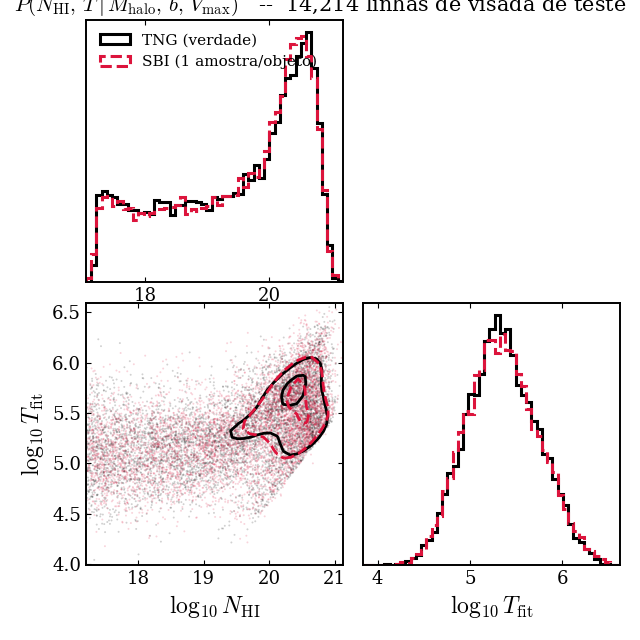

log_nhi     media 19.452 -> 19.476 | sigma 1.105 -> 1.097 | KS D=0.0155
log_T       media  5.350 ->  5.352 | sigma 0.381 -> 0.391 | KS D=0.0129


In [79]:
# ==============================================================================
# CELL 8a -- Population corner: truth (TNG) vs SBI
# ==============================================================================
USE_MEDIAN = False    # False = 1 sample/object (posterior predictive); True = median

if USE_MEDIAN:
    theta_pred = np.median(inferred_theta_test, axis=1)
    pred_label = 'SBI (posterior median)'
else:
    idx = rng.integers(0, inferred_theta_test.shape[1], inferred_theta_test.shape[0])
    theta_pred = inferred_theta_test[np.arange(len(idx)), idx]
    pred_label = 'SBI (1 sample/object)'


def corner_population(theta_true, theta_pred, titles,
                      c_true='k', c_pred='crimson', label_true='TNG (truth)',
                      label_pred='SBI', nbins=40, levels=(0.68, 0.95),
                      fontsize=17, max_scatter=6000):
    """Corner comparing two POPULATIONS in the same theta space.

    Diagonal : marginal histograms of both.
    Off-diag : scatter + density contours (68% and 95%) of both.
    """
    D = theta_true.shape[1]
    fig, axs = plt.subplots(D, D, figsize=(3.2 * D, 3.2 * D))
    if D == 1:
        axs = np.array([[axs]])

    sub = (np.random.default_rng(0).choice(len(theta_true), max_scatter, replace=False)
           if len(theta_true) > max_scatter else slice(None))

    def contours(ax, x, y, color, ls):
        xi, yi = np.mgrid[x.min():x.max():nbins * 1j, y.min():y.max():nbins * 1j]
        if len(x) > 20000:   # KDE is O(n_data * n_eval); 20k already saturates the contour
            kk = np.random.default_rng(0).choice(len(x), 20000, replace=False)
            x, y = x[kk], y[kk]
        zi = sp.stats.gaussian_kde(np.vstack([x, y]))(
            np.vstack([xi.ravel(), yi.ravel()])).reshape(xi.shape)
        zi /= zi.sum()
        t = np.linspace(0, zi.max(), 1000)
        integral = ((zi >= t[:, None, None]) * zi).sum(axis=(1, 2))
        tc = np.sort(sp.interpolate.interp1d(integral, t)(
            np.array([1 - l for l in levels])))
        ax.contour(zi.T, tc, extent=[x.min(), x.max(), y.min(), y.max()],
                   colors=[color], linewidths=2.0, linestyles=ls)

    for i in range(D):
        for j in range(i + 1, D):
            axs[i, j].set_axis_off()

        ax = axs[i, i]
        lo = min(theta_true[:, i].min(), theta_pred[:, i].min())
        hi = max(theta_true[:, i].max(), theta_pred[:, i].max())
        bins = np.linspace(lo, hi, 50)
        ax.hist(theta_true[:, i], bins=bins, density=True, histtype='step',
                color=c_true, lw=2.2, label=label_true)
        ax.hist(theta_pred[:, i], bins=bins, density=True, histtype='step',
                color=c_pred, lw=2.2, ls='--', label=label_pred)
        ax.set_yticks([])
        ax.set_xlim(lo, hi)
        if i == 0:
            ax.legend(fontsize=11, loc='upper left', frameon=False)

        for j in range(i + 1, D):
            ax = axs[j, i]
            ax.scatter(theta_true[sub, i], theta_true[sub, j], s=2, c=c_true,
                       alpha=0.18, edgecolor='none', rasterized=True)
            ax.scatter(theta_pred[sub, i], theta_pred[sub, j], s=2, c=c_pred,
                       alpha=0.18, edgecolor='none', rasterized=True)
            contours(ax, theta_true[:, i], theta_true[:, j], c_true, '-')
            contours(ax, theta_pred[:, i], theta_pred[:, j], c_pred, '--')
            ax.set_xlim(theta_true[:, i].min(), theta_true[:, i].max())
            ax.set_ylim(theta_true[:, j].min(), theta_true[:, j].max())
            if i == 0:
                ax.set_ylabel(titles[j], fontsize=fontsize)
            else:
                ax.set_yticklabels([])
        axs[-1, i].set_xlabel(titles[i], fontsize=fontsize)
        if i > 0:
            axs[i, i].set_yticklabels([])
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.08, wspace=0.08)
    return fig, axs


fig, axs = corner_population(theta_test, theta_pred, THETA_TITLES,
                             label_pred=pred_label)
fig.suptitle(r'$P(N_{\rm HI},\, T \mid M_{\rm halo},\, b,\, V_{\rm max})$'
             f'   --  {len(theta_test):,} test sightlines',
             y=1.01, fontsize=15)
plt.show()

# how well the two populations agree, marginal by marginal
for i, k in enumerate(THETA_KEYS):
    ks = sp.stats.ks_2samp(theta_test[:, i], theta_pred[:, i])
    print(f"{k:10s}  media {theta_test[:, i].mean():6.3f} -> {theta_pred[:, i].mean():6.3f}"
          f" | sigma {theta_test[:, i].std():5.3f} -> {theta_pred[:, i].std():5.3f}"
          f" | KS D={ks.statistic:.4f}")

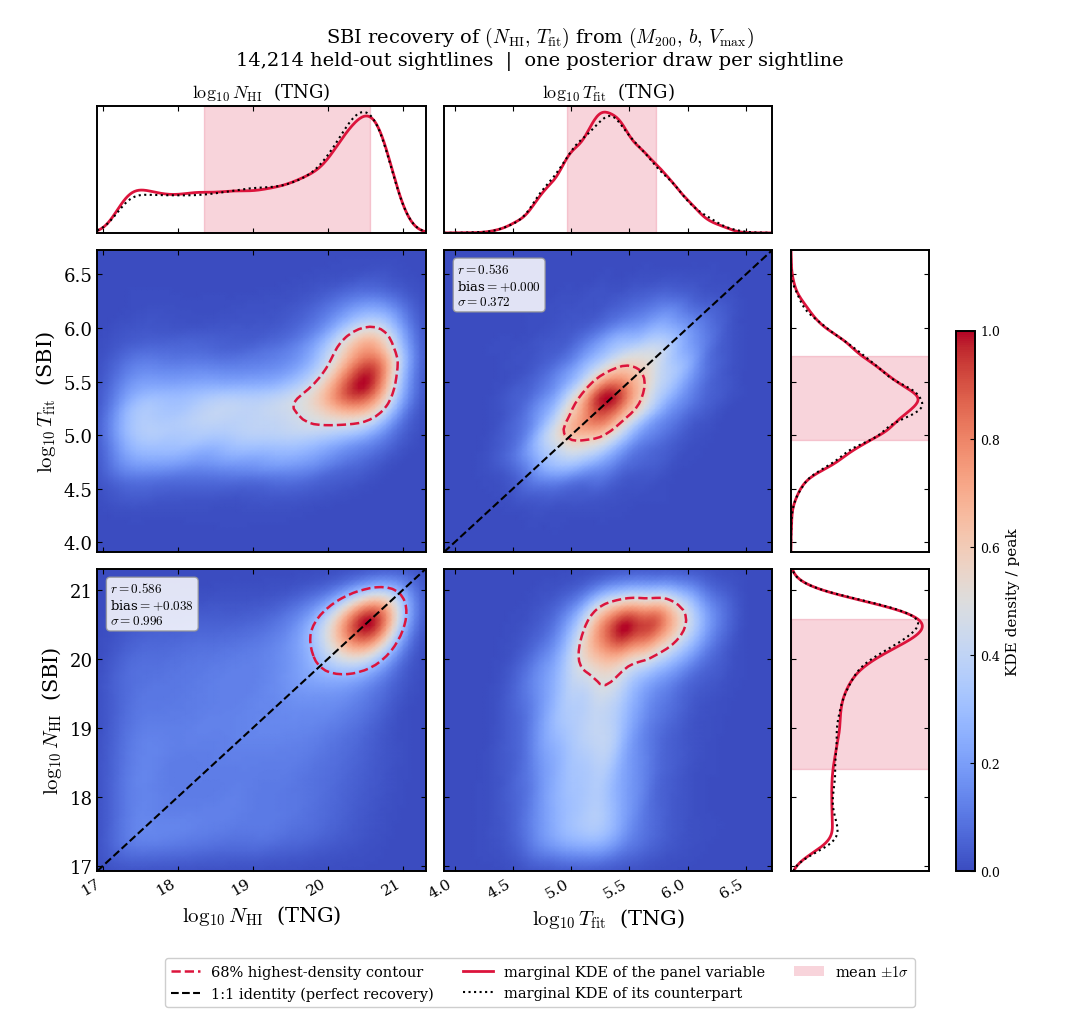

GLOBAL
  log N_HI                 n=14,214  mean  19.452 ->  19.490  std  1.105 ->  1.084  r= 0.586  bias=+0.038  sigma=0.996  KS D=0.0196
  log T_fit                n=14,214  mean   5.350 ->   5.351  std  0.381 ->  0.391  r= 0.536  bias=+0.000  sigma=0.372  KS D=0.0130

low  (N_HI < 19.0)
  log N_HI                 n= 4,796  mean  18.086 ->  18.746  std  0.531 ->  0.964  r= 0.100  bias=+0.660  sigma=1.053  KS D=0.4033
  log T_fit                n= 4,796  mean   5.132 ->   5.161  std  0.302 ->  0.335  r= 0.295  bias=+0.028  sigma=0.379  KS D=0.0488

high (N_HI > 19.0)
  log N_HI                 n= 9,418  mean  20.147 ->  19.869  std  0.515 ->  0.935  r= 0.523  bias=-0.279  sigma=0.797  KS D=0.1831
  log T_fit                n= 9,418  mean   5.461 ->   5.448  std  0.370 ->  0.382  r= 0.521  bias=-0.014  sigma=0.368  KS D=0.0244


In [80]:
# ==============================================================================
# CELL 8 -- Truth vs inferred: full 2x2 matrix with edge marginals
#
# WHAT THIS SHOWS
#   Columns are the TNG values, rows are the SBI values, so each 2D panel is a
#   joint density over the whole held-out set.
#
#     bottom-left  N_HI(SBI) vs N_HI(TNG)   recovery test, with the 1:1 line
#     middle       T(SBI)    vs T(TNG)      recovery test, with the 1:1 line
#     top-left     T(SBI)    vs N_HI(TNG)   cross term
#     bottom-mid   N_HI(SBI) vs T(TNG)      cross term
#
#   The cross terms show how much the network leans on the N_HI-T correlation
#   it learned during training.
#
# NAMING
#   `fit_T` in the pipeline is the Voigt-fit temperature measured on the TNG
#   spectrum -- it IS theta[1], the truth the network infers. So "fit" cannot
#   also mean "SBI output"; axes are labelled (TNG) and (SBI). Note this is
#   fit_T, NOT T_sim (the N_HI-weighted simulation temperature).
#
# READING THE STATS BOX
#   r      Pearson correlation between TNG and SBI
#   bias   mean offset in dex, should sit near zero
#   sigma  scatter about the 1:1 line = the irreducible uncertainty, i.e. how
#          much (M200, b, Vmax) genuinely fails to determine the quantity
#   CAUTION: if the conditional is multimodal, a single posterior draw can land
#   in either mode, which inflates sigma and deflates r even for a perfect
#   model. In that case judge the fit by whether the marginals overlap, and
#   recompute the stats within each mode.
#
# ELEMENTS
#   coolwarm map   KDE density of the pair, each panel scaled to its own peak
#   crimson dashed smallest region containing PROB of the density
#   black dashed   1:1 identity
#   crimson solid  marginal KDE of that panel's variable
#   black dotted   marginal KDE of its counterpart (TNG vs SBI of the same
#                  quantity) -- overlap means the population was reproduced
#   pink band      mean +/- 1 sigma of the crimson marginal
# ==============================================================================
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

CMAP, C_CONT, C_ID, C_CPT = 'coolwarm', 'crimson', 'k', 'k'
PROB = 0.68


def _kde2(x, y, xl, yl, n=60, mx=20000):
    """KDE of (x, y) on a grid. Subsampled: KDE is O(n_data * n_eval)."""
    if len(x) > mx:
        k = np.random.default_rng(0).choice(len(x), mx, replace=False)
        x, y = x[k], y[k]
    xi, yi = np.mgrid[xl[0]:xl[1]:n * 1j, yl[0]:yl[1]:n * 1j]
    zi = sp.stats.gaussian_kde(np.vstack([x, y]))(
        np.vstack([xi.ravel(), yi.ravel()])).reshape(xi.shape)
    return xi, yi, zi


def _level(zi, prob):
    """Density threshold of the smallest region holding `prob` of the mass."""
    z = zi / zi.sum()
    t = np.linspace(0, z.max(), 1000)
    I = ((z >= t[:, None, None]) * z).sum(axis=(1, 2))
    return float(sp.interpolate.interp1d(I, t)(1 - prob)) * zi.sum()


def _sty(ax):
    [s.set_linewidth(1.4) for s in ax.spines.values()]
    ax.tick_params(which='both', direction='in', top=True, right=True)


def _panel(ax, x, y, xl, yl, identity=False):
    xi, yi, zi = _kde2(x, y, xl, yl)
    pc = ax.pcolormesh(xi, yi, zi / zi.max(), shading='gouraud',
                       cmap=CMAP, vmin=0, vmax=1)
    ax.contour(xi, yi, zi, levels=[_level(zi, PROB)], colors=[C_CONT],
               linewidths=1.8, linestyles='--')
    if identity:
        lo, hi = max(xl[0], yl[0]), min(xl[1], yl[1])
        ax.plot([lo, hi], [lo, hi], color=C_ID, lw=1.5, ls='--')
        ax.text(0.04, 0.96,
                f"$r={np.corrcoef(x, y)[0, 1]:.3f}$\n"
                f"bias$={np.mean(y - x):+.3f}$\n$\\sigma={np.std(y - x):.3f}$",
                transform=ax.transAxes, va='top', ha='left', fontsize=9.5,
                bbox=dict(fc='white', ec='0.6', alpha=0.85,
                          boxstyle='round,pad=0.3'))
    ax.set_xlim(*xl)
    ax.set_ylim(*yl)
    return pc


def _marg(ax, v, counterpart, xl, rot=False):
    g = np.linspace(*xl, 300)
    d = sp.stats.gaussian_kde(v)(g)
    dc = sp.stats.gaussian_kde(counterpart)(g)
    m, s = v.mean(), v.std()
    if rot:                                    # row marginal: density on x
        ax.plot(d, g, color=C_CONT, lw=2.0)
        ax.plot(dc, g, color=C_CPT, lw=1.5, ls=':')
        ax.axhspan(m - s, m + s, color=C_CONT, alpha=0.18)
        ax.set_ylim(*xl); ax.set_xlim(0, None)
        ax.set_yticklabels([]); ax.set_xticks([])
    else:                                      # column marginal: density on y
        ax.plot(g, d, color=C_CONT, lw=2.0)
        ax.plot(g, dc, color=C_CPT, lw=1.5, ls=':')
        ax.axvspan(m - s, m + s, color=C_CONT, alpha=0.18)
        ax.set_xlim(*xl); ax.set_ylim(0, None)
        ax.set_xticklabels([]); ax.set_yticks([])


# ---- one SBI value per test object ------------------------------------------
# A single posterior draw, not the median: the median averages over the
# posterior width and would shrink the inferred scatter, so the two populations
# would stop being comparable. It would also erase the bimodality entirely.
USE_MEDIAN = False

if USE_MEDIAN:
    theta_pred = np.median(inferred_theta_test, axis=1)
    draw_note = 'posterior median per sightline'
else:
    _i = rng.integers(0, inferred_theta_test.shape[1],
                      inferred_theta_test.shape[0])
    theta_pred = inferred_theta_test[np.arange(len(_i)), _i]
    draw_note = 'one posterior draw per sightline'

n_tng, t_tng = theta_test[:, 0], theta_test[:, 1]
n_sbi, t_sbi = theta_pred[:, 0], theta_pred[:, 1]

PAD = 0.02
def _lim(*arrs):
    v = np.concatenate(arrs)
    lo, hi = v.min(), v.max()
    p = PAD * (hi - lo)
    return (lo - p, hi + p)

Ln, Lt = _lim(n_tng, n_sbi), _lim(t_tng, t_sbi)

TN_R = r'$\log_{10} N_{\rm HI}$  (TNG)'
TT_R = r'$\log_{10} T_{\rm fit}$  (TNG)'
TN_S = r'$\log_{10} N_{\rm HI}$  (SBI)'
TT_S = r'$\log_{10} T_{\rm fit}$  (SBI)'

fig = plt.figure(figsize=(10.8, 10.2))
gs = fig.add_gridspec(3, 3, width_ratios=[1, 1, 0.42],
                      height_ratios=[0.42, 1, 1], hspace=0.07, wspace=0.07,
                      left=0.09, right=0.86, top=0.895, bottom=0.145)

# ---- top marginals: the TNG quantities ---------------------------------------
a00 = fig.add_subplot(gs[0, 0]); _sty(a00)
_marg(a00, n_tng, n_sbi, Ln)
a00.set_title(TN_R, fontsize=13, pad=6)

a01 = fig.add_subplot(gs[0, 1]); _sty(a01)
_marg(a01, t_tng, t_sbi, Lt)
a01.set_title(TT_R, fontsize=13, pad=6)

# ---- row 1: T (SBI) ----------------------------------------------------------
a10 = fig.add_subplot(gs[1, 0]); _sty(a10)
pc = _panel(a10, n_tng, t_sbi, Ln, Lt)
a10.set_ylabel(TT_S, fontsize=15); a10.set_xticklabels([])

a11 = fig.add_subplot(gs[1, 1]); _sty(a11)
_panel(a11, t_tng, t_sbi, Lt, Lt, identity=True)      # T recovery test
a11.set_xticklabels([]); a11.set_yticklabels([])

a12 = fig.add_subplot(gs[1, 2]); _sty(a12)
_marg(a12, t_sbi, t_tng, Lt, rot=True)

# ---- row 2: N_HI (SBI) -------------------------------------------------------
a20 = fig.add_subplot(gs[2, 0]); _sty(a20)
_panel(a20, n_tng, n_sbi, Ln, Ln, identity=True)      # N_HI recovery test
a20.set_ylabel(TN_S, fontsize=15); a20.set_xlabel(TN_R, fontsize=15)

a21 = fig.add_subplot(gs[2, 1]); _sty(a21)
_panel(a21, t_tng, n_sbi, Lt, Ln)
a21.set_xlabel(TT_R, fontsize=15); a21.set_yticklabels([])

a22 = fig.add_subplot(gs[2, 2]); _sty(a22)
_marg(a22, n_sbi, n_tng, Ln, rot=True)

for ax in (a20, a21):
    for t in ax.get_xticklabels():
        t.set_rotation(30); t.set_ha('right'); t.set_fontsize(11)

# ---- legend below, colourbar on the right ------------------------------------
fig.legend(
    [Line2D([0], [0], color=C_CONT, lw=1.8, ls='--'),
     Line2D([0], [0], color=C_ID, lw=1.5, ls='--'),
     Line2D([0], [0], color=C_CONT, lw=2.0),
     Line2D([0], [0], color=C_CPT, lw=1.5, ls=':'),
     Patch(fc=C_CONT, alpha=0.18, ec='none')],
    [f'{int(PROB*100)}% highest-density contour',
     '1:1 identity (perfect recovery)',
     'marginal KDE of the panel variable',
     'marginal KDE of its counterpart',
     r'mean $\pm 1\sigma$'],
    loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3,
    fontsize=10.5, frameon=True, framealpha=0.95)

cax = fig.add_axes([0.885, 0.145, 0.018, 0.53])
cb = fig.colorbar(pc, cax=cax)
cb.set_label('KDE density / peak', fontsize=11)
cb.ax.tick_params(labelsize=9)

fig.suptitle(
    r'SBI recovery of $(N_{\rm HI},\,T_{\rm fit})$ from '
    r'$(M_{200},\,b,\,V_{\rm max})$'
    f'\n{len(theta_test):,} held-out sightlines  |  {draw_note}',
    fontsize=14, y=0.975)
plt.show()

# ---- population agreement, globally and per N_HI mode ------------------------
# Pearson r and the 1:1 scatter are only meaningful within a single mode, so
# they are also reported split at the gap between the two N_HI populations.
NHI_MODE_SPLIT = 19.0

def _stats(tag, xt, xp):
    ks = sp.stats.ks_2samp(xt, xp)
    print(f"{tag:26s} n={len(xt):6,}  mean {xt.mean():7.3f} -> {xp.mean():7.3f}"
          f"  std {xt.std():6.3f} -> {xp.std():6.3f}"
          f"  r={np.corrcoef(xt, xp)[0, 1]:6.3f}"
          f"  bias={np.mean(xp - xt):+6.3f}  sigma={np.std(xp - xt):5.3f}"
          f"  KS D={ks.statistic:.4f}")

print("GLOBAL")
_stats("  log N_HI", n_tng, n_sbi)
_stats("  log T_fit", t_tng, t_sbi)

for tag, m in [(f"low  (N_HI < {NHI_MODE_SPLIT})", n_tng < NHI_MODE_SPLIT),
               (f"high (N_HI > {NHI_MODE_SPLIT})", n_tng >= NHI_MODE_SPLIT)]:
    if m.sum() > 50:
        print(f"\n{tag}")
        _stats("  log N_HI", n_tng[m], n_sbi[m])
        _stats("  log T_fit", t_tng[m], t_sbi[m])

---

## Notes

**The `good` cut is a selection, not a neutral filter.** The network learns
`P(N_HI, T | M, b, V_max, T constrained)`. Since T is only measurable while the damping
wings do not dominate, the cut preferentially removes the DLAs -- the per-class numbers
printed in CELL 3 show the size of the effect. This is a property of the problem (not of
the network): no fit, no T. Worth saying explicitly in any text that uses this result.

**The prior is not the physical prior.** `dict_bounds` is a box over the observed range of
`(log N_HI, log T)` in the training set. It is what `sbi` uses to correct leakage in
`build_posterior`. The effective distribution of `theta` in training is the empirical one of
the stratified sample, not uniform -- so the posterior is "the posterior given how this run
sampled halos", which is the standard for amortised NPE on a fixed dataset.

**SBIBE's `compute_ranks` is wrong.** `np.argsort(tmp, axis=1)[:, 0, :]` returns the index of
the smallest element, not the rank of the truth. Under perfect calibration both give a flat
histogram, so it goes unnoticed; but the original cannot see posteriors that are too wide.
Test with a posterior 2x wider than the correct one: the right rank gives the characteristic
arc, SBIBE's stays flat. The version in CELL 5 is fixed.

**Natural next steps**: rank statistics / SBC (Daniel's `plot_rank_statistcis`, now with the
right rank), merge the 5 seeds, add `c200` via `rs.add_concentration`, and the resolution
test training on TNG50-2 and evaluating on 50-3 / 50-4 -- which is exactly the
`modelA1 / modelA2 / modelR` structure of Daniel's `preprocessing_tools.py`.

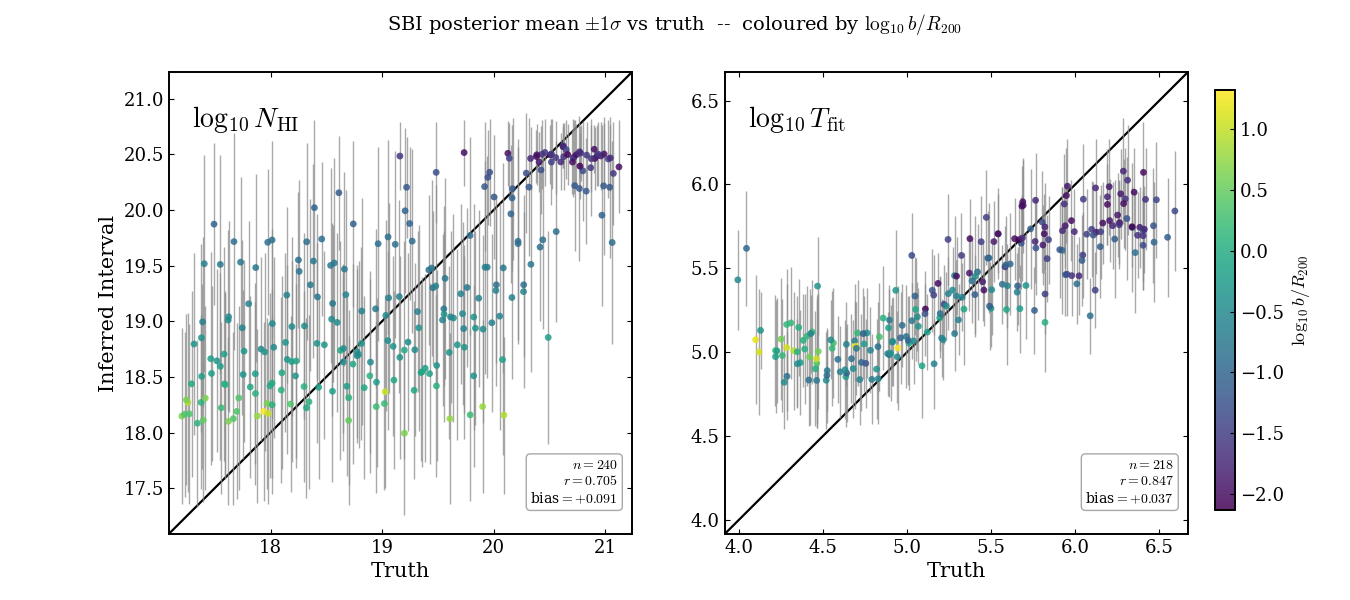

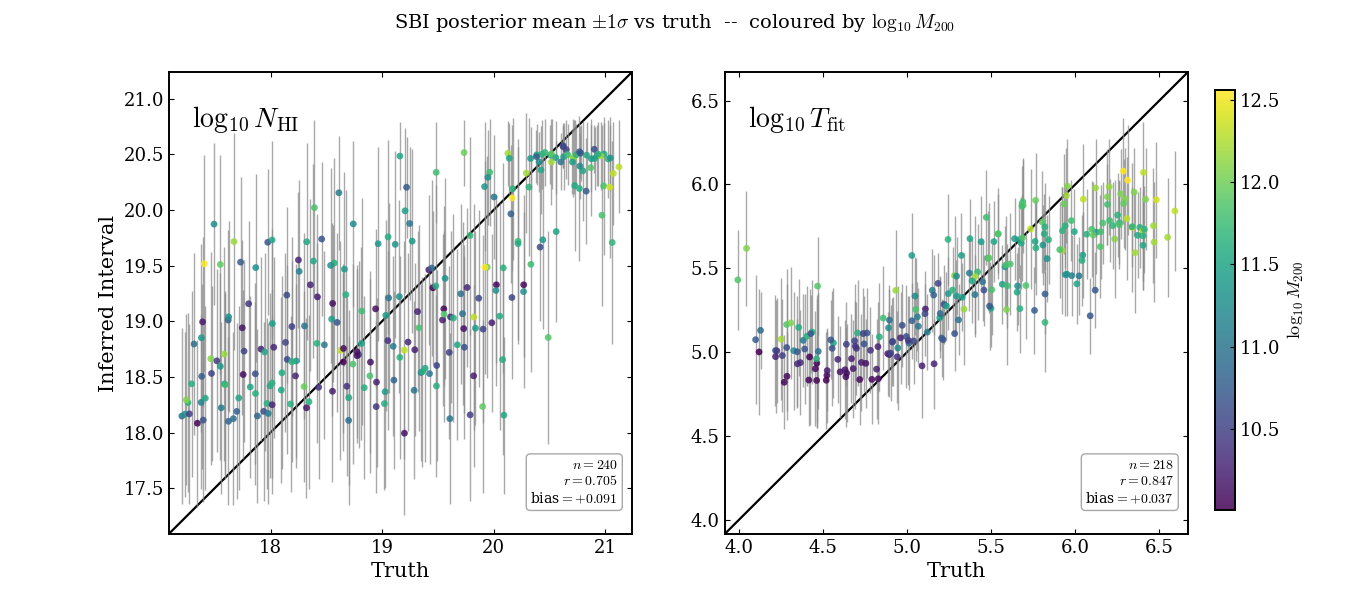

In [81]:
# ==============================================================================
# CELL 9 -- Posterior mean +/- 1 sigma against the truth
#
# Two panels, one per parameter. For each held-out sightline: x = the TNG value,
# y = the mean of the SBI posterior, error bar = its standard deviation. The
# black line is 1:1.
#
# REPRESENTATIVE SAMPLING
#   Plotting all sightlines is unreadable and, worse, misleading: the sample is
#   heavily concentrated near the low-N_HI pile-up just above the 10^17.2 cut,
#   so a random subset would show almost nothing at high N_HI. `representative
#   _indices` bins the x range uniformly and draws the same number from each
#   bin, so the plot covers the span of the quantity rather than its density.
#   Each panel gets its OWN sample, drawn uniform in ITS OWN x variable.
#   Set N_SHOW = None to plot everything.
#
# COLOURING
#   COLOR_KEYS picks which conditioning variables to colour by; one figure per
#   entry. Colouring by log b is the informative one: if the network is doing
#   its job, colour should vary smoothly ALONG the 1:1 line (b drives N_HI) and
#   NOT across it. Structure perpendicular to the line means a systematic the
#   network is not capturing.
# ==============================================================================
N_SHOW = 250                    # points per panel; None = plot all
COLOR_KEYS = ['log_b', 'log_M200']      # one figure each; [] = no colouring
XX_TITLES = [r'$\log_{10} M_{200}$', r'$\log_{10} b/R_{200}$',
             r'$\log_{10} V_{\rm max}$']

post_mean = inferred_theta_test.mean(axis=1)
post_std = inferred_theta_test.std(axis=1)


def representative_indices(x, n_show, n_bins=None, seed=0):
    """Indices covering the RANGE of x uniformly, not its density."""
    x = np.asarray(x, float)
    if n_show is None or n_show >= len(x):
        return np.arange(len(x))
    n_bins = n_bins or min(n_show, 40)
    edges = np.linspace(x.min(), x.max(), n_bins + 1)
    which = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1)
    r = np.random.default_rng(seed)
    per = max(1, int(round(n_show / n_bins)))
    picks = []
    for b in range(n_bins):
        idx = np.where(which == b)[0]
        if idx.size:
            picks.append(r.choice(idx, min(per, idx.size), replace=False))
    return np.concatenate(picks) if picks else np.arange(0)


def truth_vs_pred(theta_true, mean, std, titles, color_vals=None,
                  color_label='', cmap='viridis', n_show=250,
                  figsize=(13.5, 6.0), seed=0, ms=4, elw=1.0, alpha=0.85):
    D = theta_true.shape[1]
    fig, axs = plt.subplots(1, D, figsize=figsize)
    if D == 1:
        axs = np.array([axs])
    sc = None
    for i, ax in enumerate(axs):
        [s.set_linewidth(1.4) for s in ax.spines.values()]
        ax.tick_params(which='both', direction='in', top=True, right=True)

        sel = representative_indices(theta_true[:, i], n_show, seed=seed + i)
        x, y, e = theta_true[sel, i], mean[sel, i], std[sel, i]
        c = None if color_vals is None else color_vals[sel]

        lo = min(x.min(), (y - e).min())
        hi = max(x.max(), (y + e).max())
        pad = 0.03 * (hi - lo)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color='k', lw=1.6,
                zorder=1)

        if c is None:
            ax.errorbar(x, y, yerr=e, fmt='o', ms=ms, color='darkmagenta',
                        elinewidth=elw, capsize=0, alpha=alpha, zorder=3)
        else:
            # bars in grey, markers coloured: a colour-mapped errorbar would
            # need one call per point and hides the colour behind the bar
            ax.errorbar(x, y, yerr=e, fmt='none', ecolor='0.55',
                        elinewidth=elw, capsize=0, alpha=0.75, zorder=2)
            sc = ax.scatter(x, y, c=c, cmap=cmap, s=ms**2 + 8, zorder=3,
                            edgecolor='none', alpha=alpha)

        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_xlabel('Truth', fontsize=15)
        if i == 0:
            ax.set_ylabel('Inferred Interval', fontsize=15)
        ax.text(0.05, 0.93, titles[i], transform=ax.transAxes, fontsize=20,
                va='top')
        ax.text(0.97, 0.06,
                f"$n={len(sel)}$\n$r={np.corrcoef(x, y)[0, 1]:.3f}$\n"
                f"bias$={np.mean(y - x):+.3f}$",
                transform=ax.transAxes, ha='right', va='bottom', fontsize=10,
                bbox=dict(fc='white', ec='0.6', alpha=0.85,
                          boxstyle='round,pad=0.3'))

    if sc is not None:
        fig.subplots_adjust(right=0.88)
        cax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
        fig.colorbar(sc, cax=cax).set_label(color_label, fontsize=13)
    return fig, axs


if not COLOR_KEYS:
    fig, _ = truth_vs_pred(theta_test, post_mean, post_std, THETA_TITLES,
                           n_show=N_SHOW)
    fig.suptitle(r'SBI posterior mean $\pm 1\sigma$ vs truth',
                 fontsize=14, y=0.98)
    plt.show()
else:
    for key in COLOR_KEYS:
        j = XX_KEYS.index(key)
        fig, _ = truth_vs_pred(theta_test, post_mean, post_std, THETA_TITLES,
                               color_vals=xx_test[:, j],
                               color_label=XX_TITLES[j], n_show=N_SHOW)
        fig.suptitle(r'SBI posterior mean $\pm 1\sigma$ vs truth'
                     f'  --  coloured by {XX_TITLES[j]}', fontsize=14, y=0.98)
        plt.show()

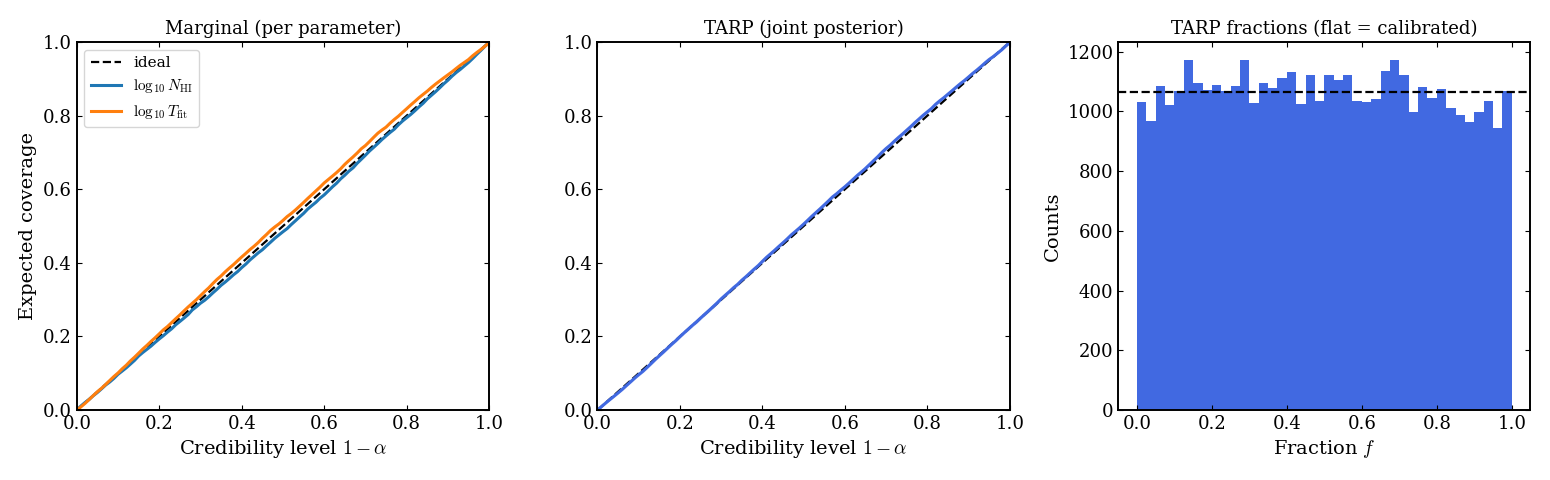

max |ECP - ideal|
  marginal log_nhi    0.0169
  marginal log_T      0.0223
  TARP (joint)          0.0114


In [82]:
# ==============================================================================
# CELL 10 -- Coverage test
#
# Two complementary versions, because they answer different questions.
#
# MARGINAL COVERAGE (left panel)
#   For each credibility level c, the fraction of sightlines whose truth falls
#   inside the central-c interval of the 1D marginal posterior. One curve per
#   parameter. Diagonal = calibrated. This checks each parameter separately and
#   is blind to how the network gets the CORRELATION between them.
#
# TARP (middle and right panels; Lemos et al. 2023, arXiv:2302.03026)
#   Tests the JOINT posterior. For each sightline, draw a random reference
#   point, measure the distance from it to the truth, and record f = the
#   fraction of posterior samples that are closer to the reference than the
#   truth is. If the posterior is calibrated, f is uniform on [0, 1], so the
#   ECP curve (its empirical CDF) is the diagonal and the histogram of f is
#   flat. Deviations have characteristic shapes: overconfident posteriors pile
#   f up at both ends, underconfident ones bunch it in the middle.
#
#   Parameters are standardised before distances are taken -- without it,
#   log N_HI (spanning ~4 dex) would swamp log T (~2 dex) in the norm and TARP
#   would effectively test N_HI alone.
#
# TARP IS THE STRICTER TEST. In a check on a deliberately miscalibrated toy,
# the marginal curve sat on the diagonal to 0.008 while TARP deviated by 0.11.
# If the two disagree, believe TARP.
# ==============================================================================
N_REF_DRAWS = 3        # independent reference-point sets, pooled
N_BOOT = 200           # bootstrap resamples for the TARP band
LEVELS = np.linspace(0.0, 1.0, 101)


def marginal_coverage(truth, samples, levels):
    """Fraction of truths inside the central-c interval, per parameter."""
    ecp = np.zeros((len(levels), truth.shape[1]))
    for k, lv in enumerate(levels):
        lo = np.percentile(samples, 100 * (1 - lv) / 2, axis=1)
        hi = np.percentile(samples, 100 * (1 + lv) / 2, axis=1)
        ecp[k] = np.mean((truth >= lo) & (truth <= hi), axis=0)
    return ecp


def tarp_fractions(truth, samples, seed=0, n_ref=1):
    """TARP f statistic. Uniform on [0,1] iff the joint posterior is calibrated."""
    mu, sd = truth.mean(0), truth.std(0)          # standardise, see header
    th, sm = (truth - mu) / sd, (samples - mu) / sd
    r = np.random.default_rng(seed)
    out = []
    for _ in range(n_ref):
        ref = r.uniform(th.min(0), th.max(0), size=th.shape)
        d_truth = np.linalg.norm(th - ref, axis=-1)               # (N,)
        d_samp = np.linalg.norm(sm - ref[:, None, :], axis=-1)    # (N, S)
        out.append((d_samp < d_truth[:, None]).mean(axis=1))
    return np.concatenate(out)


def ecp_from_fractions(f, levels):
    return np.array([(f < c).mean() for c in levels])


ecp_marg = marginal_coverage(theta_test, inferred_theta_test, LEVELS)
f_tarp = tarp_fractions(theta_test, inferred_theta_test, n_ref=N_REF_DRAWS)
ecp_tarp = ecp_from_fractions(f_tarp, LEVELS)

# bootstrap band over the sightlines
_boot = np.zeros((N_BOOT, len(LEVELS)))
_rb = np.random.default_rng(1)
for b in range(N_BOOT):
    _boot[b] = ecp_from_fractions(f_tarp[_rb.integers(0, len(f_tarp),
                                                      len(f_tarp))], LEVELS)
blo, bhi = np.percentile(_boot, [16, 84], axis=0)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.8))
for ax in axs:
    [s.set_linewidth(1.4) for s in ax.spines.values()]
    ax.tick_params(which='both', direction='in', top=True, right=True)

ax = axs[0]
ax.plot([0, 1], [0, 1], 'k--', lw=1.6, label='ideal')
for i, t in enumerate(THETA_TITLES):
    ax.plot(LEVELS, ecp_marg[:, i], lw=2.2, label=t)
ax.set_xlabel(r'Credibility level $1-\alpha$', fontsize=14)
ax.set_ylabel('Expected coverage', fontsize=14)
ax.set_title('Marginal (per parameter)', fontsize=13)
ax.legend(fontsize=11, loc='upper left')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = axs[1]
ax.plot([0, 1], [0, 1], 'k--', lw=1.6)
ax.fill_between(LEVELS, blo, bhi, color='royalblue', alpha=0.3)
ax.plot(LEVELS, ecp_tarp, color='royalblue', lw=2.2)
ax.set_xlabel(r'Credibility level $1-\alpha$', fontsize=14)
ax.set_title('TARP (joint posterior)', fontsize=13)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = axs[2]
ax.hist(f_tarp, bins=40, range=(0, 1), color='royalblue')
ax.axhline(len(f_tarp) / 40, color='k', ls='--', lw=1.6)
ax.set_xlabel(r'Fraction $f$', fontsize=14)
ax.set_ylabel('Counts', fontsize=14)
ax.set_title('TARP fractions (flat = calibrated)', fontsize=13)

plt.tight_layout()
plt.show()

print("max |ECP - ideal|")
for i, k in enumerate(THETA_KEYS):
    print(f"  marginal {k:10s} {np.abs(ecp_marg[:, i] - LEVELS).max():.4f}")
print(f"  TARP (joint)          {np.abs(ecp_tarp - LEVELS).max():.4f}")

In [83]:
for i, k in enumerate(THETA_KEYS):
    x, y = theta_test[:, i], post_mean[:, i]
    r = np.corrcoef(x, y)[0, 1]
    slope = np.polyfit(x, y, 1)[0]
    print(f"{k:10s} r={r:.3f}  r^2={r**2:.3f}  slope={slope:.3f}")

lo = np.array([dict_bounds[k][0] for k in THETA_KEYS])
hi = np.array([dict_bounds[k][1] for k in THETA_KEYS])
outside = (theta_test < lo) | (theta_test > hi)
for i, k in enumerate(THETA_KEYS):
    print(f"{k:10s} outside the prior: {100*outside[:, i].mean():.2f}%  "
          f"(box [{lo[i]:.2f}, {hi[i]:.2f}], test goes up to {theta_test[:, i].max():.2f})")
lb = xx_test[:, XX_KEYS.index('log_b')]
for q0, q1 in zip([0, 33, 66], [33, 66, 100]):
    a, b_ = np.percentile(lb, [q0, q1])
    m = (lb >= a) & (lb <= b_)
    f = tarp_fractions(theta_test[m], inferred_theta_test[m], n_ref=N_REF_DRAWS)
    d = np.abs(ecp_from_fractions(f, LEVELS) - LEVELS).max()
    print(f"log b in [{a:+.2f}, {b_:+.2f}]  n={m.sum():5,}  TARP dev={d:.4f}")

log_nhi    r=0.764  r^2=0.583  slope=0.579
log_T      r=0.732  r^2=0.535  slope=0.545
log_nhi    fora do prior: 0.00%  (box [17.00, 21.30], teste vai ate 21.12)
log_T      fora do prior: 0.00%  (box [3.63, 6.78], teste vai ate 6.59)
log b em [-2.13, -1.23]  n=5,055  TARP dev=0.0046
log b em [-1.23, -0.60]  n=5,486  TARP dev=0.0077
log b em [-0.60, +1.70]  n=5,457  TARP dev=0.0067
